Dimensiones (filas, columnas): (20640, 9)

Tipos de datos:
 MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Valores nulos por columna:
 MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Estadísticos descriptivos:
                count         mean          std         min          50%  \
MedInc       20640.0     3.870671     1.899822    0.499900     3.534800   
HouseAge     20640.0    28.639486    12.585558    1.000000    29.000000   
AveRooms     20640.0     5.429000     2.474173    0.846154     5.229129   
AveBedrms    20640.0     1.096675     0.473911    0.333333     1.048780   
Population   20640.0  1425.476744  1132.462122    3.000000  1166.000000   
AveOccup     20640.0     3.070655    10.38605

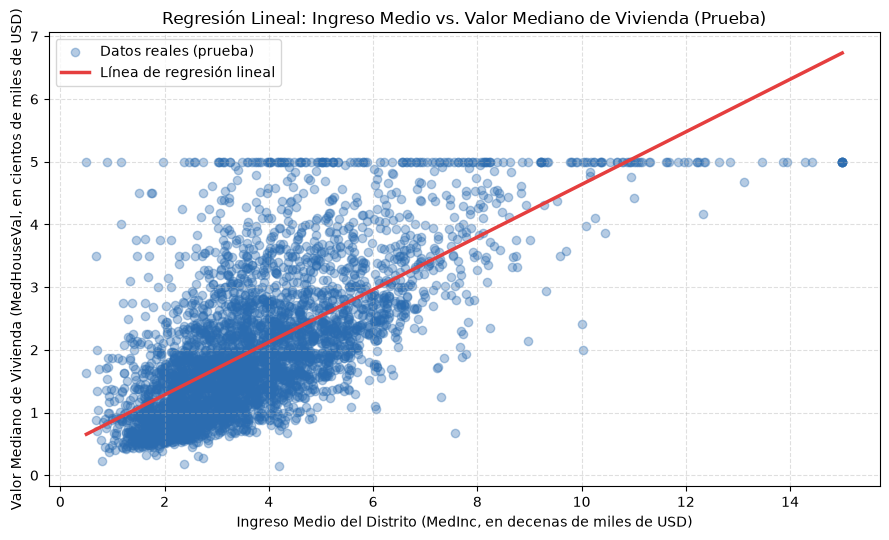

In [5]:
# 1. Importación de librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Semilla fija de reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 2. Carga del conjunto de datos (California Housing)
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

# Inspección inicial
print("Dimensiones (filas, columnas):", df.shape)
print("\nTipos de datos:\n", df.dtypes)
print("\nValores nulos por columna:\n", df.isnull().sum())
print("\nEstadísticos descriptivos:\n", df.describe().T[["count", "mean", "std", "min", "50%", "max"]])

# Revisión rápida de valores atípicos (IQR) en la variable objetivo y variables clave
Q1 = df["MedHouseVal"].quantile(0.25)
Q3 = df["MedHouseVal"].quantile(0.75)
IQR = Q3 - Q1
outliers_y = df[(df["MedHouseVal"] < Q1 - 1.5 * IQR) | (df["MedHouseVal"] > Q3 + 1.5 * IQR)]
print(f"\nPosibles atípicos en MedHouseVal (regla 1.5*IQR): {len(outliers_y)} registros")

# 3. Definición de características (X) y variable objetivo (y)
# Para graficar fácilmente la línea de regresión en 2D, usamos 'MedInc' (ingreso medio)
# Si deseas regresión lineal múltiple, usa todas las columnas excepto 'MedHouseVal'.
X = df[["MedInc"]]
y = df["MedHouseVal"]

# 4. División en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

# 5. Ajuste del modelo de Regresión Lineal y predicción en prueba
modelo = LinearRegression()
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)

# 6. Cálculo de métricas: MSE, RMSE y R²
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\nIntercepto (b0): {modelo.intercept_:.4f}")
print(f"Pendiente / Coeficiente de MedInc (b1): {modelo.coef_[0]:.4f}")
print(f"MSE (Error Cuadrático Medio): {mse:.4f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): {rmse:.4f}")
print(f"R² (Coeficiente de Determinación): {r2:.4f}")

# 7. Visualización: dispersión + línea de regresión
plt.figure(figsize=(9, 5.5))
plt.scatter(X_test["MedInc"], y_test, alpha=0.35, color="#2b6cb0", label="Datos reales (prueba)")

# Ordenar X_test para trazar la recta de forma limpia
orden = np.argsort(X_test["MedInc"].values)
x_sorted = X_test["MedInc"].values[orden]
y_pred_sorted = y_pred[orden]

plt.plot(x_sorted, y_pred_sorted, color="#e53e3e", linewidth=2.5, label="Línea de regresión lineal")

plt.title("Regresión Lineal: Ingreso Medio vs. Valor Mediano de Vivienda (Prueba)")
plt.xlabel("Ingreso Medio del Distrito (MedInc, en decenas de miles de USD)")
plt.ylabel("Valor Mediano de Vivienda (MedHouseVal, en cientos de miles de USD)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Dimensiones: (200, 2)
Valores nulos:
 Ingreso_Anual_kUSD    0
Puntaje_Gasto         0
dtype: int64
Filas duplicadas: 89


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

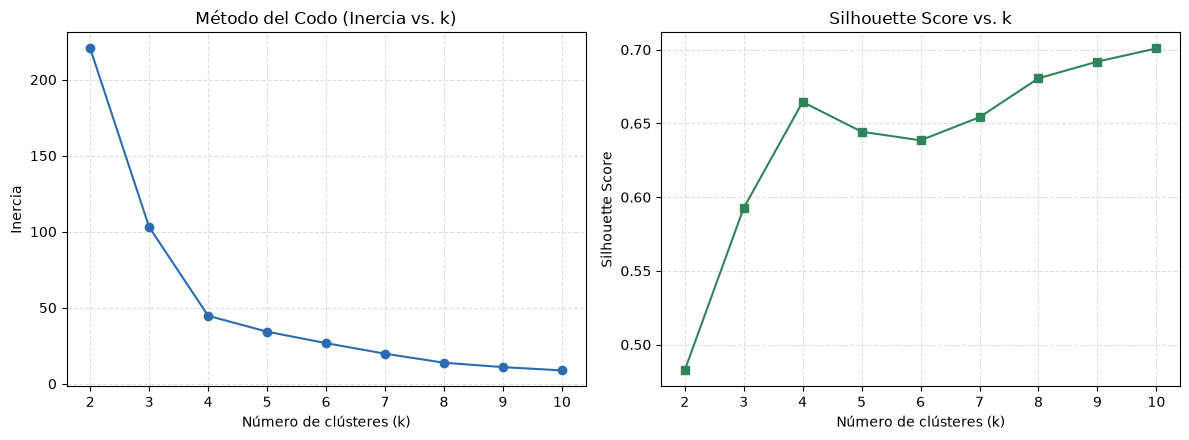

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



Centroides en escala original:
          Ingreso_Anual_kUSD  Puntaje_Gasto
Cluster                                   
0                     16.97          90.24
1                    125.51          13.63
2                    135.55          95.22
3                     25.22           7.88
4                     74.04          95.46

Perfil promedio por clúster:
          Cantidad  Ingreso_Promedio_kUSD  Gasto_Promedio
Cluster                                                 
0              71                  16.97           90.24
1              30                 125.51           13.63
2              34                 135.55           95.22
3              45                  25.22            7.88
4              20                  74.04           95.46


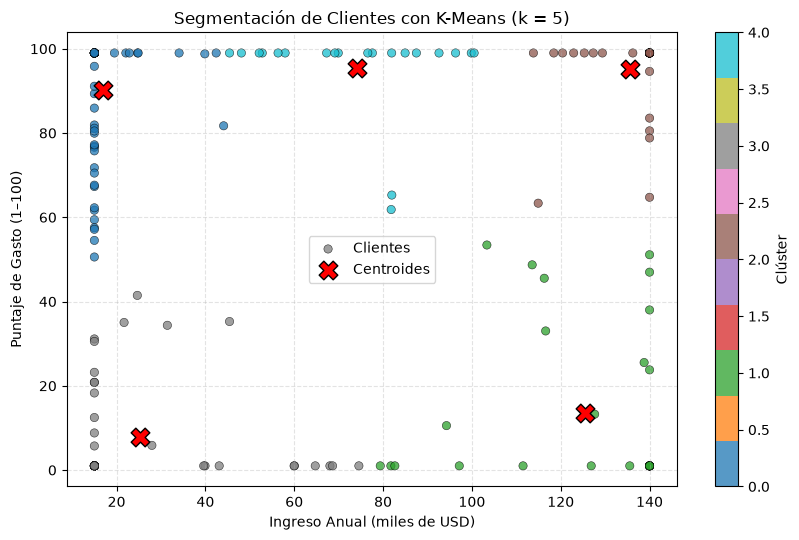

In [6]:
# 1. Importación de librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Semilla fija de reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 2. Conjunto de datos de segmentación de clientes (sintético equivalente a Mall Customers)
# Si ya cuentas con un CSV de Mall Customers, puedes cargarlo con pd.read_csv(...)
X_raw, _ = make_blobs(
    n_samples=200,
    centers=5,
    cluster_std=[12.0, 10.0, 11.0, 10.5, 11.0],
    random_state=RANDOM_STATE,
)

df_clientes = pd.DataFrame({
    "Ingreso_Anual_kUSD": np.clip(X_raw[:, 0] * 12 + 60, 15, 140),
    "Puntaje_Gasto": np.clip(X_raw[:, 1] * 12 + 50, 1, 99),
})

# Verificación de nulos y duplicados
print("Dimensiones:", df_clientes.shape)
print("Valores nulos:\n", df_clientes.isnull().sum())
print("Filas duplicadas:", df_clientes.duplicated().sum())

# 3. Escalamiento con StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clientes)

# 4. Selección de k: Método del codo (inercia) y Silhouette Score
inertias = []
sil_scores = []
k_values = range(2, 11)

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(list(k_values), inertias, marker="o", color="#2b6cb0")
axes[0].set_title("Método del Codo (Inercia vs. k)")
axes[0].set_xlabel("Número de clústeres (k)")
axes[0].set_ylabel("Inercia")
axes[0].grid(True, linestyle="--", alpha=0.4)

axes[1].plot(list(k_values), sil_scores, marker="s", color="#2f855a")
axes[1].set_title("Silhouette Score vs. k")
axes[1].set_xlabel("Número de clústeres (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# 5. Entrenamiento con k elegido (por ejemplo, k = 5) y perfil en escala original
k_optimo = 5
kmeans = KMeans(n_clusters=k_optimo, n_init=10, random_state=RANDOM_STATE)
df_clientes["Cluster"] = kmeans.fit_predict(X_scaled)

# Centroides en escala original
centroides_orig = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=["Ingreso_Anual_kUSD", "Puntaje_Gasto"],
)
centroides_orig.index.name = "Cluster"

# Perfil promedio y conteo por clúster
perfil_clusters = df_clientes.groupby("Cluster").agg(
    Cantidad=("Cluster", "count"),
    Ingreso_Promedio_kUSD=("Ingreso_Anual_kUSD", "mean"),
    Gasto_Promedio=("Puntaje_Gasto", "mean"),
)

print("\nCentroides en escala original:\n", centroides_orig.round(2))
print("\nPerfil promedio por clúster:\n", perfil_clusters.round(2))

# 6. Visualización de clústeres y centroides
plt.figure(figsize=(8.5, 5.5))
scatter = plt.scatter(
    df_clientes["Ingreso_Anual_kUSD"],
    df_clientes["Puntaje_Gasto"],
    c=df_clientes["Cluster"],
    cmap="tab10",
    alpha=0.75,
    edgecolors="k",
    linewidths=0.4,
    label="Clientes",
)

plt.scatter(
    centroides_orig["Ingreso_Anual_kUSD"],
    centroides_orig["Puntaje_Gasto"],
    c="red",
    marker="X",
    s=180,
    edgecolors="black",
    linewidths=1,
    label="Centroides",
)

plt.title(f"Segmentación de Clientes con K-Means (k = {k_optimo})")
plt.xlabel("Ingreso Anual (miles de USD)")
plt.ylabel("Puntaje de Gasto (1–100)")
plt.colorbar(scatter, label="Clúster")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

In [4]:
for k, ine, sil in zip(k_values, inertias, sil_scores):
    if k in [2, 3, 4, 5, 6]:
        print(f"k = {k} | Inercia = {ine:.2f} | Silhouette = {sil:.4f}")
        

k = 2 | Inercia = 220.51 | Silhouette = 0.4825
k = 3 | Inercia = 103.00 | Silhouette = 0.5926
k = 4 | Inercia = 44.71 | Silhouette = 0.6645
k = 5 | Inercia = 34.25 | Silhouette = 0.6444
k = 6 | Inercia = 26.71 | Silhouette = 0.6385
